this notebook plots time series acceleration vector to do a visual check

second loop, i = 0
rosbag2_2026_11_16-14_42_14: strongest tap freq = 1.83 Hz
rosbag2_2026_11_16-14_42_14: strongest accel freq = 1.83 Hz
second loop, i = 1
rosbag2_2026_11_16-14_49_18: strongest tap freq = 1.94 Hz
rosbag2_2026_11_16-14_49_18: strongest accel freq = 1.96 Hz
second loop, i = 2
rosbag2_2026_11_16-14_50_49: strongest tap freq = 1.94 Hz
rosbag2_2026_11_16-14_50_49: strongest accel freq = 0.97 Hz
second loop, i = 3
rosbag2_2026_11_16-14_40_01: strongest tap freq = 1.78 Hz
rosbag2_2026_11_16-14_40_01: strongest accel freq = 1.78 Hz
--- rosbag2_2026_11_16-14_42_14 ---
Raw Taps: 45 | Filtered Taps: 45
Avg time between steps: 1.102 seconds
Step Cadence: 1.81 Hz (108.9 steps/min)

--- rosbag2_2026_11_16-14_49_18 ---
Raw Taps: 36 | Filtered Taps: 36
Avg time between steps: 1.028 seconds
Step Cadence: 1.95 Hz (116.8 steps/min)

--- rosbag2_2026_11_16-14_50_49 ---
Raw Taps: 36 | Filtered Taps: 36
Avg time between steps: 1.041 seconds
Step Cadence: 1.92 Hz (115.3 steps/min)

--- rosb

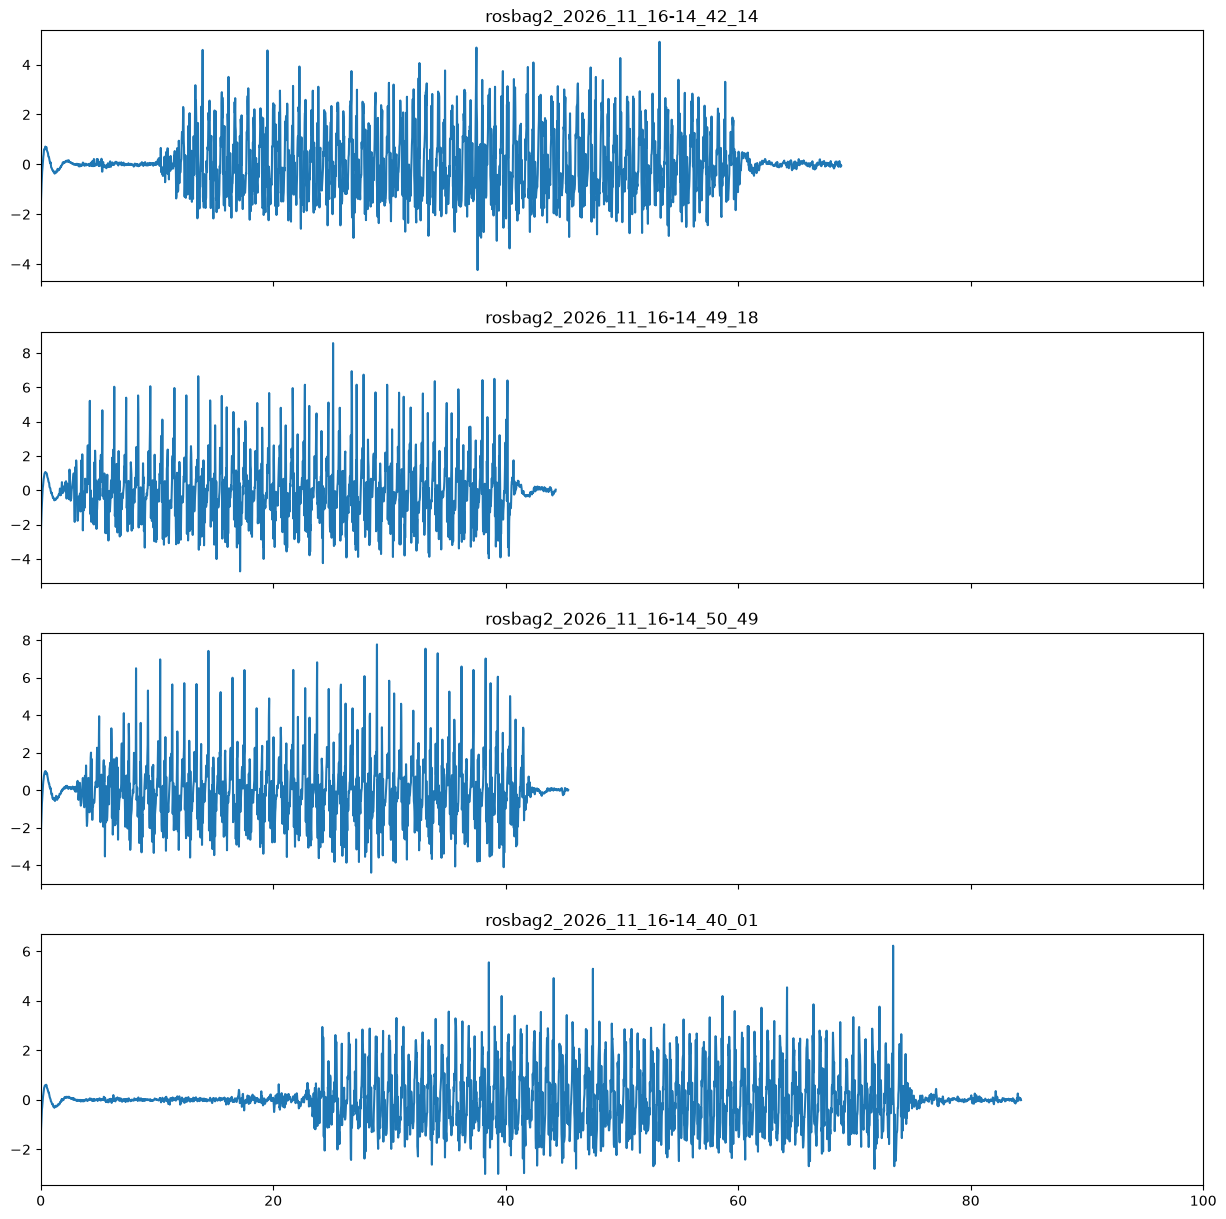

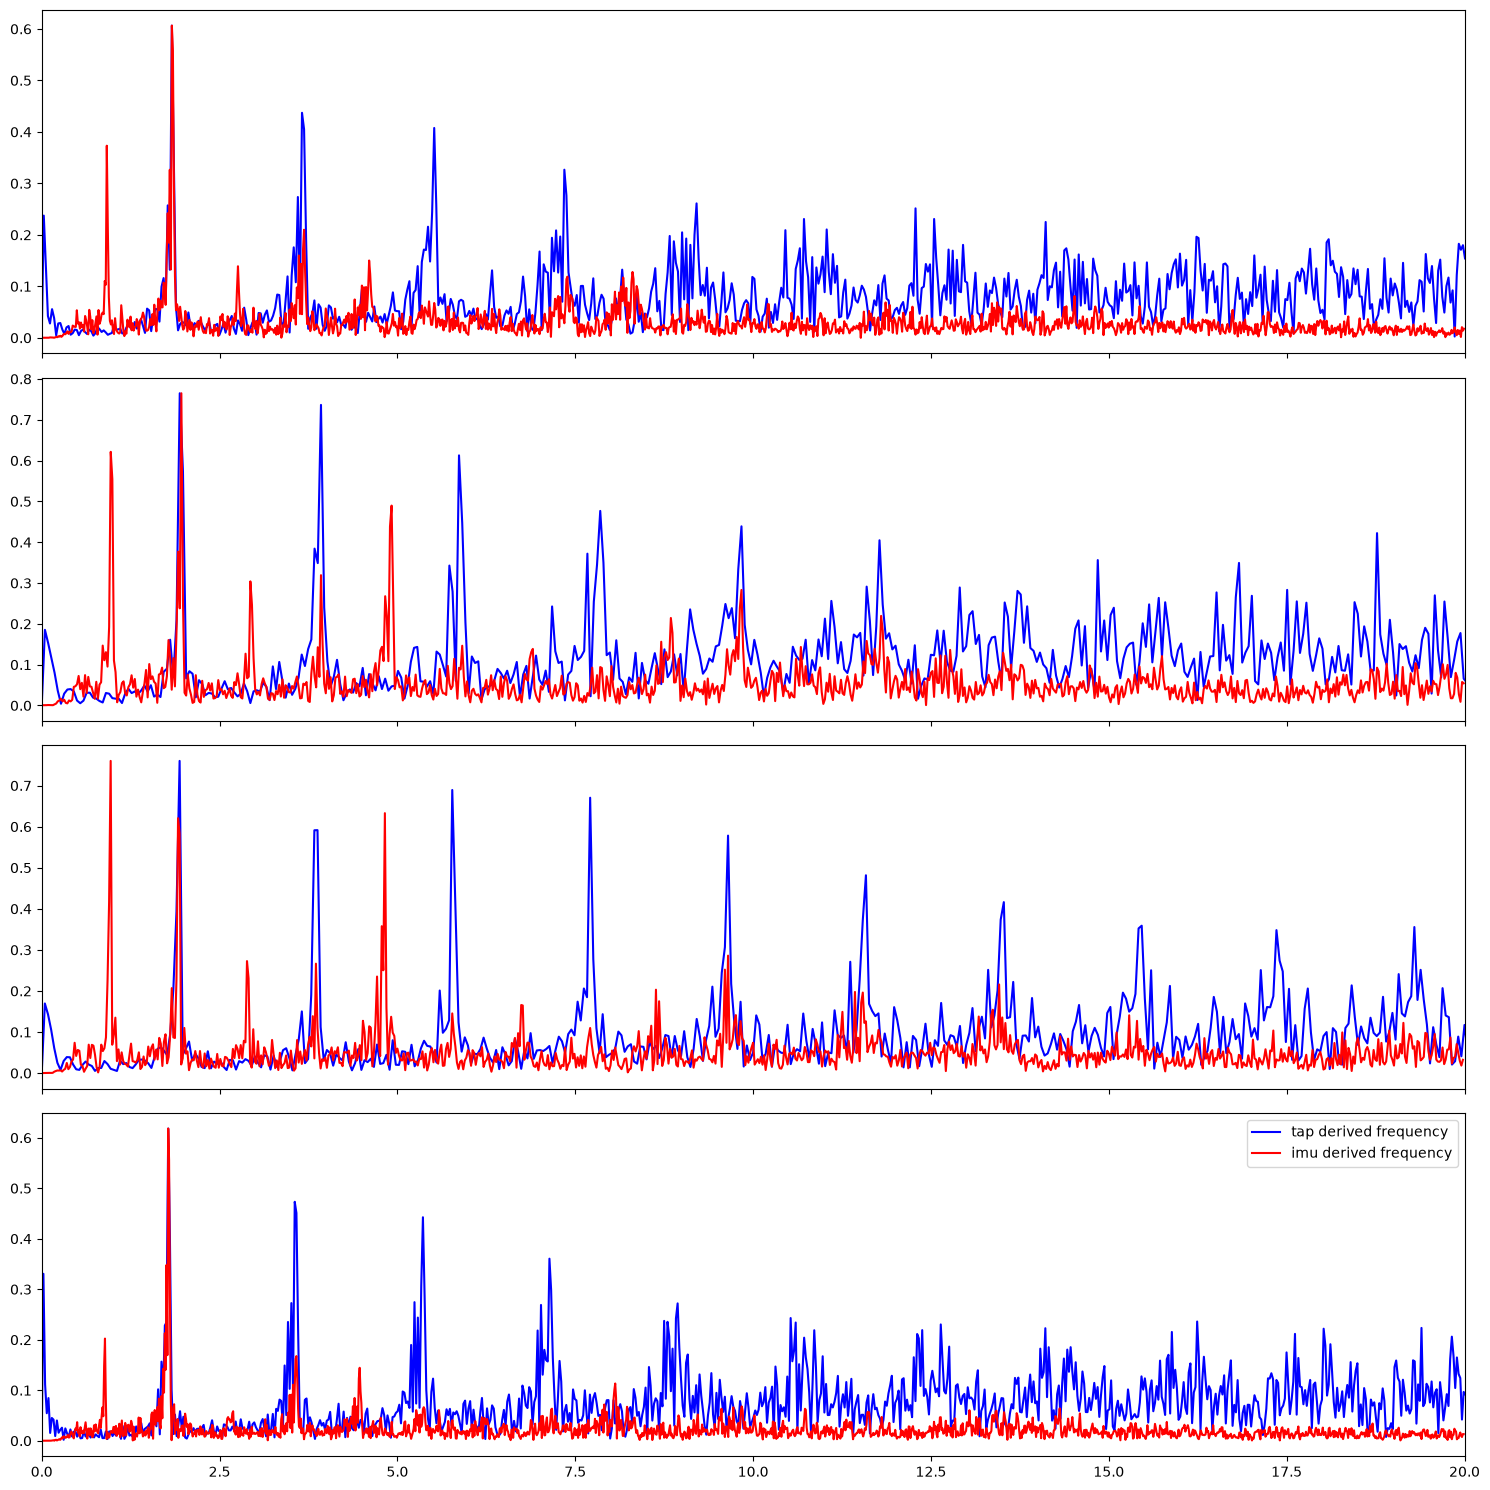

In [7]:
DATA_DIR = Path( "nov16_bags")     
#change this for whatever folder you have your bags in   

''' 
this file does FFT on accelerometer stream to find peak frequency, and compares the FFT frequency with the tap frequency
'''
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from rosbags.highlevel import AnyReader
from rosbags.typesys import Stores, get_types_from_msg, get_typestore
import math

from scipy.signal import butter, sosfilt

#ai
def highpass_filter(data, cutoff=0.5, fs=40.0, order=4):
    """
    Applies a Butterworth high-pass filter.
    
    Parameters:
    - data: 1D numpy array of your signal (e.g., norm_accel)
    - cutoff: Cutoff frequency in Hz (frequencies below this are removed)
    - fs: Sampling frequency in Hz (40.0 for your IMU)
    - order: Filter order (higher = steeper cutoff slope)
    """
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    
    # Create the filter using Second-Order Sections for stability
    sos = butter(order, normal_cutoff, btype='high', analog=False, output='sos')
    filtered_data = sosfilt(sos, data)
    return filtered_data
##end ai

IMUMSG_DEF = """
std_msgs/Header header
sensor_msgs/Imu imu
sensor_msgs/MagneticField mag_field
string raw_line
"""


add_types = get_types_from_msg(IMUMSG_DEF, "imu_msgs/msg/IMUmsg")
typestore = get_typestore(Stores.ROS2_JAZZY)
typestore.register(add_types)

def quaternion_to_euler(x, y, z, w):
    t0 = +2.0 * (w * x + y * z)
    t1 = +1.0 - 2.0 * (x * x + y * y)
    X = math.degrees(math.atan2(t0, t1))

    t2 = +2.0 * (w * y - z * x)
    t2 = +1.0 if t2 > +1.0 else t2
    t2 = -1.0 if t2 < -1.0 else t2
    Y = math.degrees(math.asin(t2))

    t3 = +2.0 * (w * z + x * y)
    t4 = +1.0 - 2.0 * (y * y + z * z)
    Z = math.degrees(math.atan2(t3, t4))

    return X, Y, Z

fig, axes = plt.subplots(4, 1, figsize=(15, 15), sharex=True)

norm_accel_all = []
walk_timestamps_all = []
names_all = [] 
frequencies_all=[]
magnitudes_all=[]
tap_timestamps_all = [] #these are discrete events
tap_frequency_all=[]


for i, item in enumerate(DATA_DIR.iterdir()):

    with AnyReader([item], default_typestore=typestore) as reader:
        accel_x, accel_y, accel_z = [], [], []
        gyro_x, gyro_y, gyro_z = [], [], []

        walk_timestamps = []
        tap_timestamps=[]
        target_topics = ["/imu", "/tap"]
        connections = [x for x in reader.connections if x.topic in target_topics]

        for connection, timestamp, rawdata in reader.messages(connections=connections):
            msg = reader.deserialize(rawdata, connection.msgtype)

            if connection.topic=="/imu":
                accel_x.append(msg.imu.linear_acceleration.x)
                accel_y.append(msg.imu.linear_acceleration.y)
                accel_z.append(msg.imu.linear_acceleration.z)

                gyro_x.append(msg.imu.angular_velocity.x)
                gyro_y.append(msg.imu.angular_velocity.y)
                gyro_z.append(msg.imu.angular_velocity.z)


                walk_timestamps.append(timestamp)
            if connection.topic=="/tap":

                tap_timestamps.append(timestamp)

 
    start_time = walk_timestamps[0]
    relative_timestamps = np.array([(t - start_time) / 1e9 for t in walk_timestamps])

    accel_x = np.array(accel_x)
    accel_y = np.array(accel_y)
    accel_z = np.array(accel_z)

    mask = relative_timestamps < 1.5
    noise_x = np.mean(accel_x[mask])
    noise_y = np.mean(accel_y[mask])
    noise_z = np.mean(accel_z[mask])

    accel_x=accel_x-noise_x
    accel_y=accel_y-noise_y
    accel_z=accel_z-noise_z
    accel_v = np.array([accel_x, accel_y, accel_z]) 
    norm_accel = np.linalg.norm(accel_v, axis=0)

    sample_frequency=100

    norm_accel_centered = norm_accel - np.mean(norm_accel)
    norm_accel_filtered = highpass_filter(norm_accel_centered, cutoff=0.5, fs=40.0, order=4)

    fft_values = np.fft.fft(norm_accel_filtered)
    fft_freqs = np.fft.fftfreq(len(norm_accel_filtered), d=1/40)  # imu uses 40 Hz sampling

    positive_mask = fft_freqs >= 0
    frequencies = fft_freqs[positive_mask]
    magnitudes = np.abs(fft_values)[positive_mask] / len(norm_accel_filtered) * 2

    frequencies_all.append(frequencies)
    magnitudes_all.append(magnitudes)

    norm_accel_all.append(norm_accel_filtered)
    walk_timestamps_all.append(relative_timestamps)
    names_all.append(item.name)
    tap_timestamps_all.append([(t - start_time) / 1e9 for t in tap_timestamps])

    

for i in range(len(norm_accel_all)):
    axes[i].plot(walk_timestamps_all[i], norm_accel_all[i])
    axes[i].set_title(names_all[i])
    axes[i].set_xlim(0, 100)


fig2, axes2 = plt.subplots(len(names_all), 1, figsize=(15, 15), sharex=True)

for i in range(len(frequencies_all)):
    print("second loop, i =", i, flush=True)
    
    relative_tap_timestamps = np.array(tap_timestamps_all[i])

    tap_signal = np.zeros(len(walk_timestamps_all[i]))

    for t_tap in relative_tap_timestamps:
        idx = np.argmin(np.abs(walk_timestamps_all[i] - t_tap))
        
        if idx < len(tap_signal):
            tap_signal[idx] = 1.0

    # CHANGE 3a: remove the DC spike
    tap_signal -= tap_signal.mean()

    tap_fft_values = np.fft.fft(tap_signal)
    tap_fft_freqs = np.fft.fftfreq(len(tap_signal), d=1/40)
    tap_positive_mask = tap_fft_freqs >= 0
    tap_frequencies = tap_fft_freqs[tap_positive_mask]
    tap_magnitudes = np.abs(tap_fft_values)[tap_positive_mask] / len(tap_signal) * 2
    tap_magnitudes = tap_magnitudes / tap_magnitudes.max() * magnitudes_all[i].max()


    peak_idx = np.argmax(tap_magnitudes[1:]) + 1   # skip the 0 Hz bin
    print(f"{names_all[i]}: strongest tap freq = {tap_frequencies[peak_idx]*2:.2f} Hz")

    band = (frequencies_all[i] > 0.5) & (frequencies_all[i] < 5)
    accel_peak = frequencies_all[i][band][np.argmax(magnitudes_all[i][band])]
    print(f"{names_all[i]}: strongest accel freq = {accel_peak:.2f} Hz")
    
    #multiply by 2 because we were only tapping every left foot strike
    axes2[i].plot(tap_frequencies *2,tap_magnitudes,color='blue',label="tap derived frequency")
    axes2[i].set_xlim(0, 20)
    axes2[i].plot(frequencies_all[i], magnitudes_all[i], color='red',label="imu derived frequency")


for i in range(0,len(names_all)): #first two have gaps
    taps = np.array(tap_timestamps_all[i])
    
    if len(taps) > 1:
        taps_sec = taps
        
        # 2. Debounce: Keep only taps separated by at least 0.2 seconds (adjust if needed)
        filtered_taps = [taps_sec[0]]
        for t in taps_sec[1:]:
            if (t - filtered_taps[-1]) >= 0.01:  # Minimum 200ms between steps
                filtered_taps.append(t)
        
        filtered_taps = np.array(filtered_taps)
        
        if len(filtered_taps) > 1:
            tap_intervals = np.diff(filtered_taps)
            avg_interval = np.mean(tap_intervals)
            
            cadence_hz = (1.0 / avg_interval )*2 #account for left foot strikes so must double time frequency
            cadence_rpm = cadence_hz * 60
            
            print(f"--- {names_all[i]} ---")
            print(f"Raw Taps: {len(taps)} | Filtered Taps: {len(filtered_taps)}")
            print(f"Avg time between steps: {avg_interval:.3f} seconds")
            print(f"Step Cadence: {cadence_hz:.2f} Hz ({cadence_rpm:.1f} steps/min)\n")
        else:
            print(f"--- {names_all[i]} ---")
            print("Not enough valid taps after filtering.\n")
    else:
        print(f"--- {names_all[i]} ---")
        print("Not enough taps recorded.\n")

plt.tight_layout()
plt.legend()
plt.show()